# Hackathon – Dataset C (COVID vaccine) · Notebook 03 of 09
## EDA part 2 – distributions, associations, interactions, cost drivers

**Module:** 7PAM2002 – University of Hertfordshire · **GitHub:** `<add link>` · **Colab:** `<add link>` · **Author of this notebook:** `<name>`

**Goal of the project:** predict which residents will accept a COVID vaccine and decide who to post a dose to so that the town's **total
cost (vaccines + hospitalisations)** is as small as possible.

<details><summary><b>The nine notebooks (run them in this order)</b></summary>

| # | Notebook | Content |
|---|---|---|
| 01 | `01_Problem_Framing_and_Cost_Metric.ipynb` | Problem framing and the task-specific cost metric |
| 02 | `02_EDA_Data_Quality.ipynb` | EDA part 1 – overview, target, missing values, data quality, train/test shift |
| 03 | `03_EDA_Feature_Relationships.ipynb` | EDA part 2 – distributions, associations, interactions, cost drivers |
| 04 | `04_Preprocessing.ipynb` | Pre-processing – cleaning, feature engineering, comparing four options |
| 05 | `05_Model_Tuning.ipynb` | Modelling – six model families and hyper-parameter tuning |
| 06 | `06_Cross_Validation_and_Decision_Strategy.ipynb` | Repeated cross-validation and turning probabilities into decisions |
| 07 | `07_Holdout_Evaluation_and_Robustness.ipynb` | Unseen hold-out evaluation, bootstrap uncertainty, robustness to assumptions |
| 08 | `08_Final_Selection_and_Submission.ipynb` | Final model selection and the five ranked submission files |
| 09 | `09_Explainable_AI_and_Conclusions.ipynb` | Explainable AI (SHAP, odds ratios, permutation importance) and conclusions |

Shared code (data loading, cost metric, cleaning, pipelines, models, evaluation helpers) lives in **`hackathon_utils.py`** so every notebook uses
exactly the same definitions. Results are passed from one notebook to the next through the **`artifacts/`** folder.
</details>


In [1]:
# ---- Set-up: run from the repository folder locally, or in Google Colab ----
import sys, os, subprocess, importlib, importlib.util
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/<your-organisation>/<your-repository>.git'   # <- set this once for Colab

if IN_COLAB and not Path('hackathon_utils.py').exists():
    subprocess.run(['git', 'clone', '-q', REPO_URL, 'repo'], check=True)   # get code, data and artifacts
    os.chdir('repo')

for pkg in ['xgboost', 'lightgbm', 'catboost', 'shap']:                    # CatBoost is not pre-installed on Colab
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from hackathon_utils import *            # shared data, cost metric, pipelines, models and helpers
print('train:', train_raw.shape, '| test:', test_raw.shape, '| scikit-learn', sklearn.__version__)

train: (4756, 31) | test: (4749, 30) | scikit-learn 1.6.1


In [2]:
from scipy import stats
from sklearn.feature_selection import mutual_info_classif

## 3. Exploratory Data Analysis – part 2
### 3.6 Univariate distributions

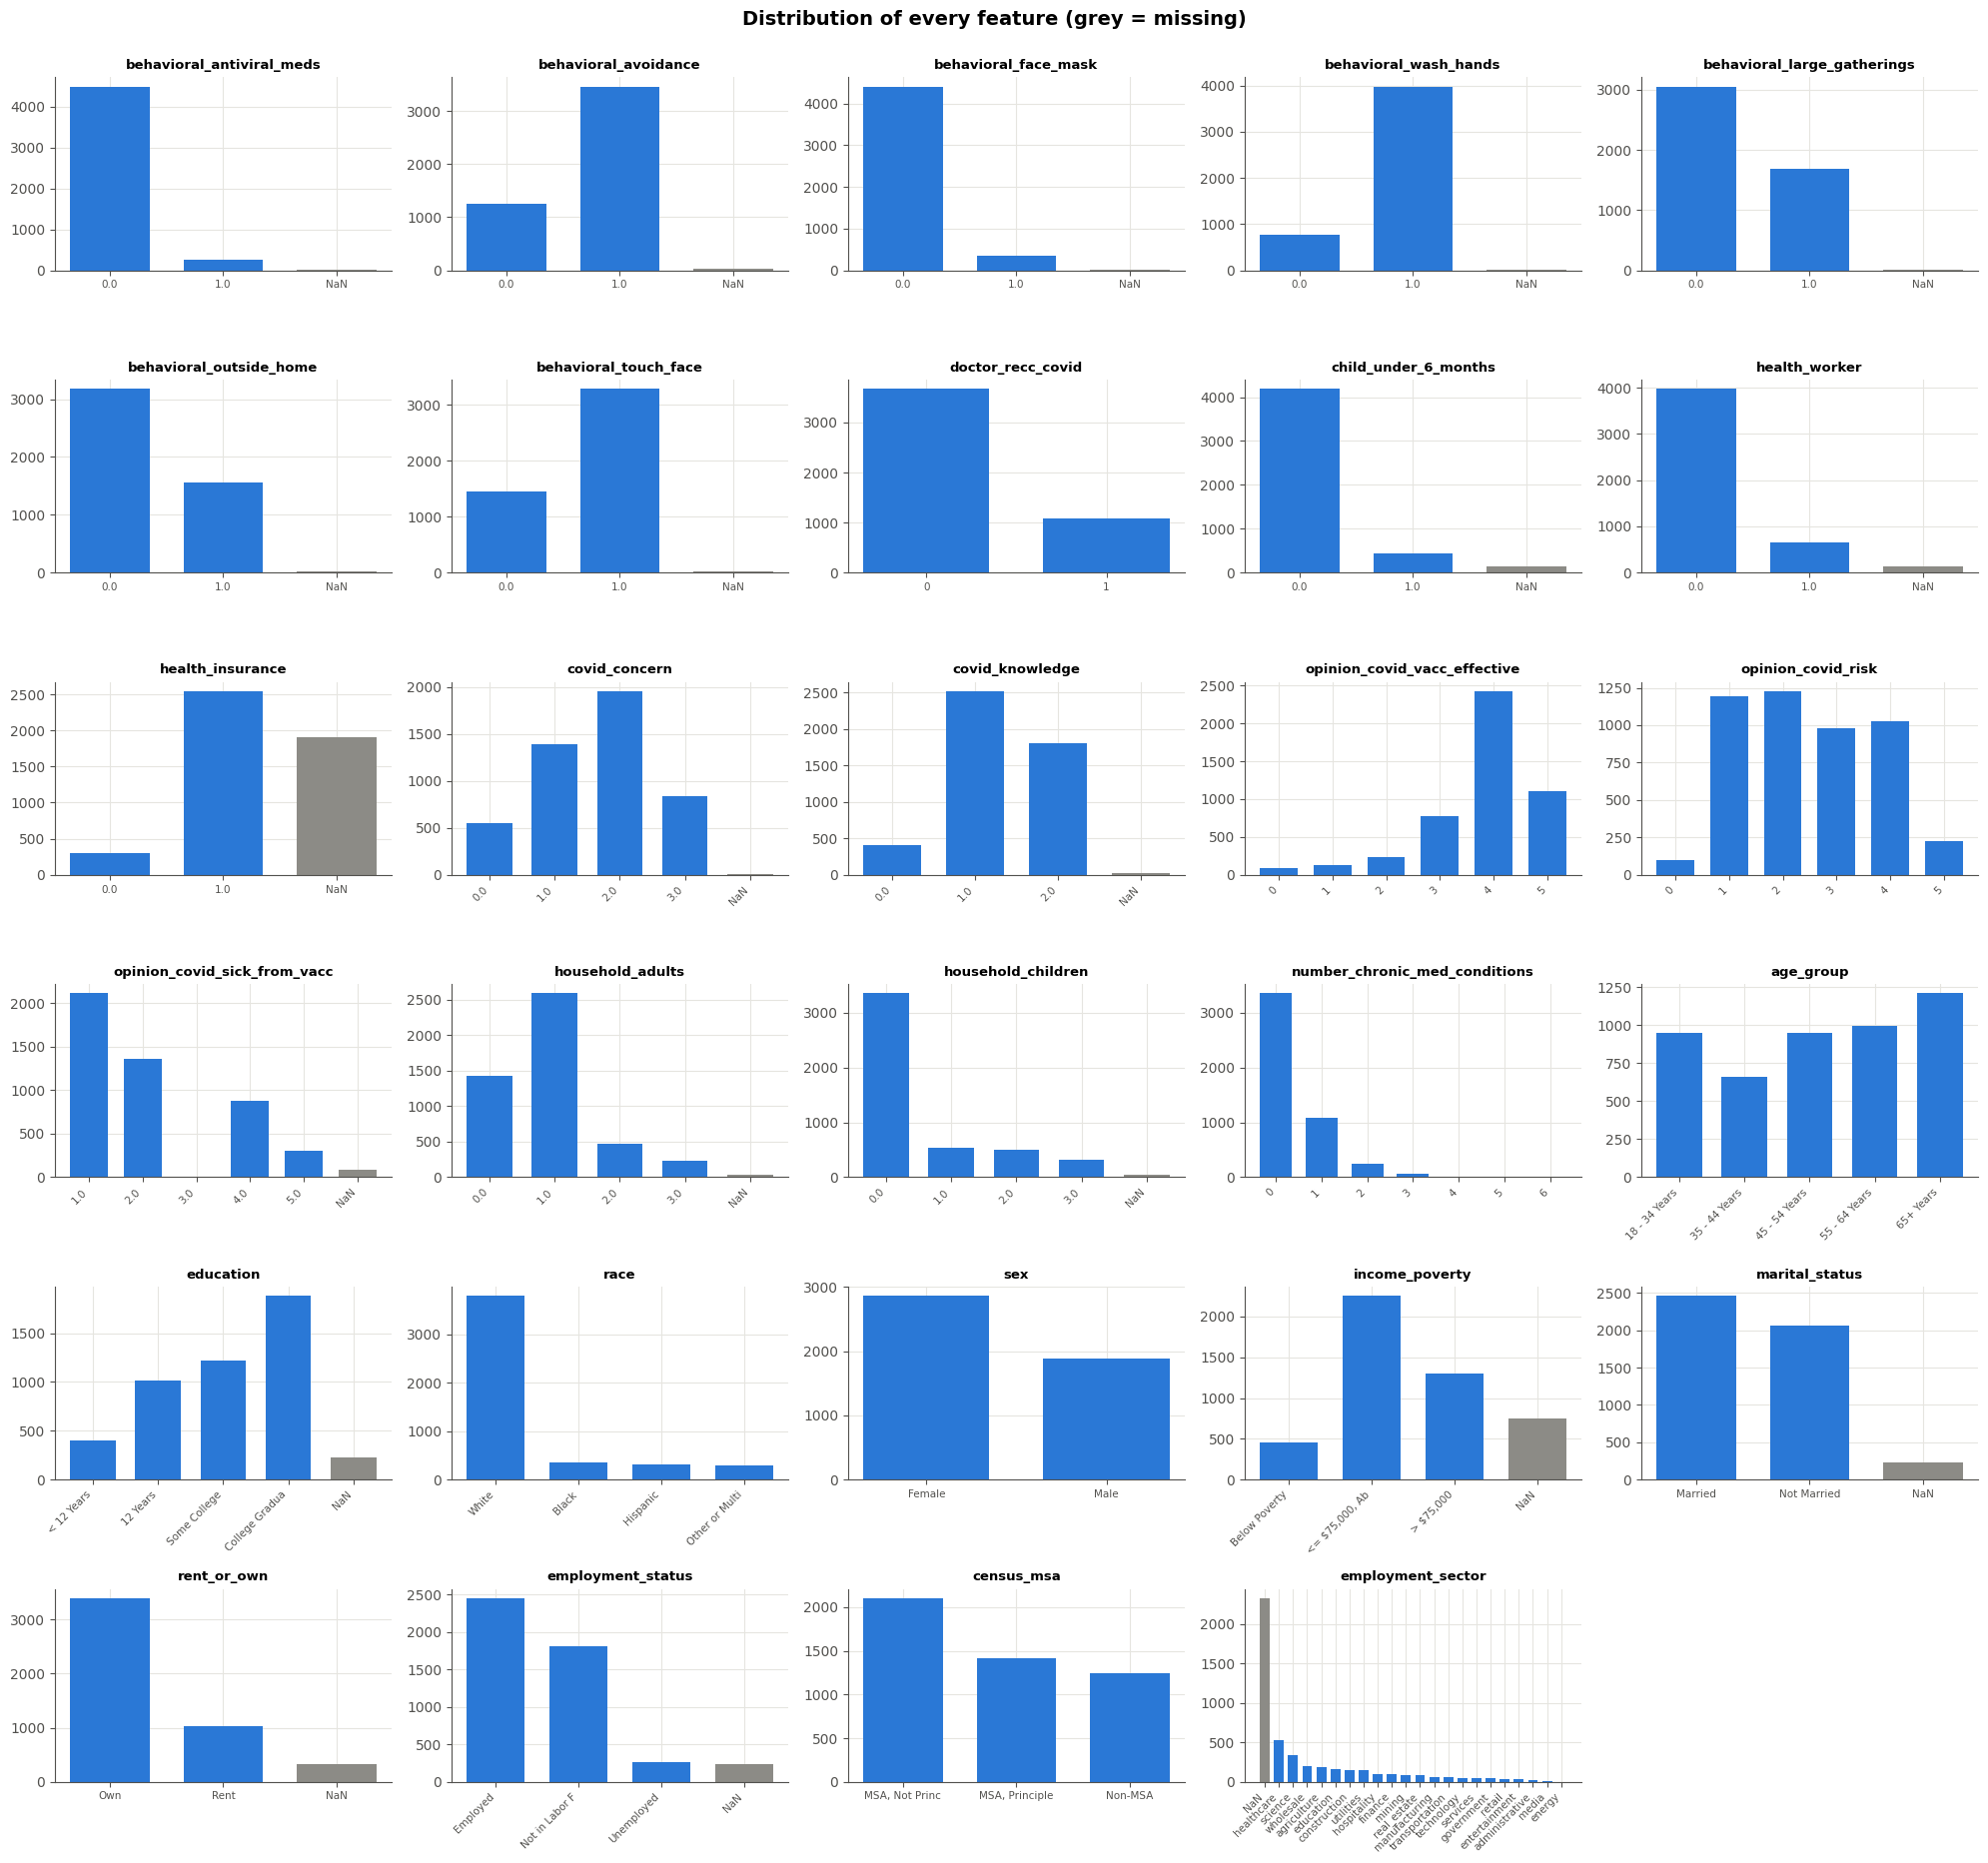

In [3]:
plot_cols = BINARY + ORDINAL_NUM + CATEGORICAL
n_cols = 5
n_rows = int(np.ceil(len(plot_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.1 * n_rows))
for ax, c in zip(axes.flat, plot_cols):
    vc = train_raw[c].fillna('NaN').astype(str).value_counts()
    if c in ['age_group', 'education', 'income_poverty']:
        order = {'age_group': AGE_ORDER, 'education': EDU_ORDER, 'income_poverty': INC_ORDER}[c]
        vc = vc.reindex([o for o in order + ['NaN'] if o in vc.index])
    elif c not in CATEGORICAL:
        vc = vc.sort_index()
    labels = [str(l)[:14] for l in vc.index]
    ax.bar(labels, vc.values, color=[GREY if l == 'NaN' else BLUE for l in vc.index], width=0.7)
    ax.set_title(c, fontsize=9.5); ax.tick_params(axis='x', labelrotation=45 if len(vc) > 3 else 0, labelsize=7.5)
    for lab in ax.get_xticklabels():
        lab.set_horizontalalignment('right' if len(vc) > 3 else 'center')
for ax in list(axes.flat)[len(plot_cols):]:
    ax.axis('off')
plt.suptitle('Distribution of every feature (grey = missing)', y=1.0, fontsize=14, fontweight='bold')
plt.tight_layout(); savefig('03_univariate'); plt.show()

Observations: most behavioural questions are heavily skewed (e.g. 80 %+ wash hands, < 5 % took antivirals); the sample is older than the
general population (25 % aged 65+); ~80 % White; `employment_sector` has many rare categories (several with < 30 people) → rare
categories will be grouped (`min_frequency` in one-hot encoding).

### 3.7 How does each feature relate to vaccine acceptance?

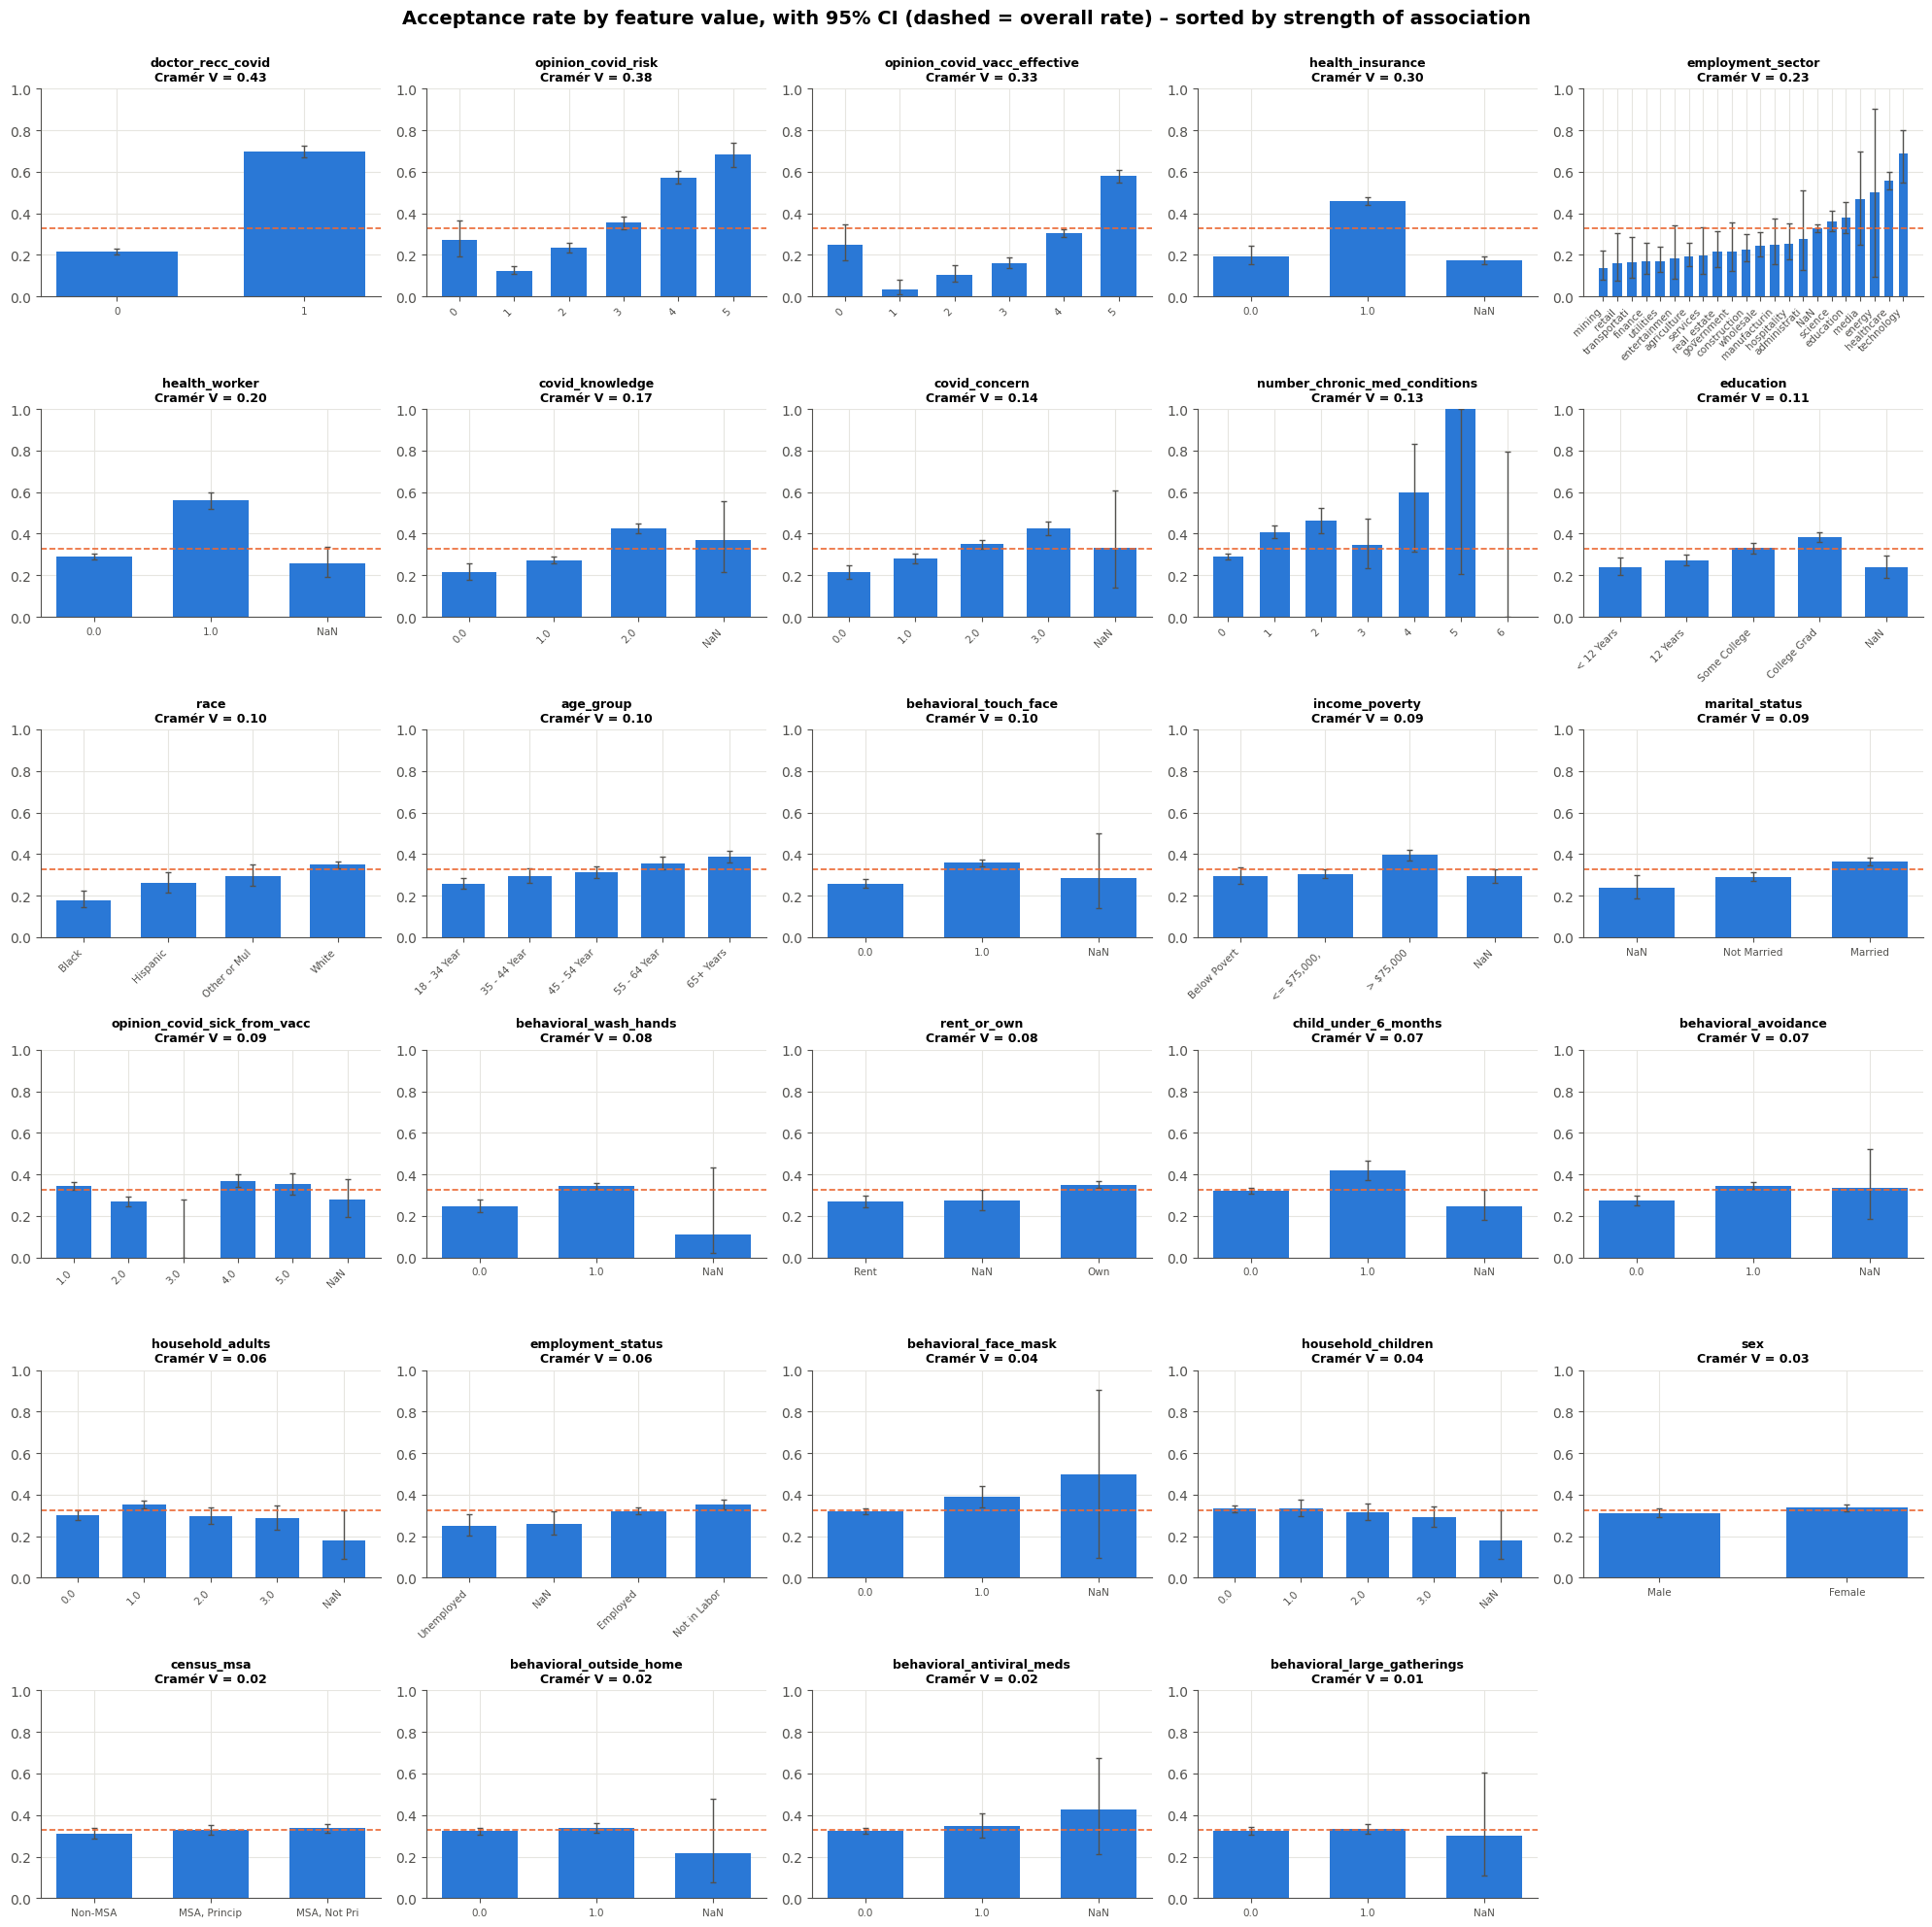

In [4]:
def wilson(k, n, z=1.96):
    # 95% Wilson confidence interval for a proportion.
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half

def cramers_v(x, y):
    ct = pd.crosstab(x.fillna('NaN').astype(str), y)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))

assoc = pd.Series({c: cramers_v(train_raw[c], train_raw[TARGET]) for c in FEATURES}).sort_values(ascending=False)
base_rate = train_raw[TARGET].mean()

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.3 * n_rows))
for ax, c in zip(axes.flat, assoc.index):
    s = train_raw[c].fillna('NaN').astype(str)
    g = train_raw.groupby(s)[TARGET].agg(['sum', 'size'])
    if c in ['age_group', 'education', 'income_poverty']:
        order = {'age_group': AGE_ORDER, 'education': EDU_ORDER, 'income_poverty': INC_ORDER}[c]
        g = g.reindex([o for o in order + ['NaN'] if o in g.index])
    elif c not in CATEGORICAL:
        g = g.sort_index()
    else:
        g = g.sort_values('sum', key=lambda _: g['sum'] / g['size'])
    rate = g['sum'] / g['size']
    lo, hi = wilson(g['sum'], g['size'])
    x = np.arange(len(g))
    ax.bar(x, rate, color=BLUE, width=0.65)
    ax.errorbar(x, rate, yerr=[rate - lo, hi - rate], fmt='none', ecolor=INK2, elinewidth=1, capsize=2)
    ax.axhline(base_rate, color=ORANGE, lw=1.2, ls='--')
    ax.set_xticks(x, [str(l)[:12] for l in g.index], rotation=45 if len(g) > 3 else 0,
                  ha='right' if len(g) > 3 else 'center', fontsize=7.5)
    ax.set_ylim(0, 1); ax.set_title(f'{c}\nCramér V = {assoc[c]:.2f}', fontsize=9)
for ax in list(axes.flat)[len(assoc):]:
    ax.axis('off')
plt.suptitle('Acceptance rate by feature value, with 95% CI (dashed = overall rate) – sorted by strength of association',
             y=1.0, fontsize=14, fontweight='bold')
plt.tight_layout(); savefig('03_bivariate'); plt.show()

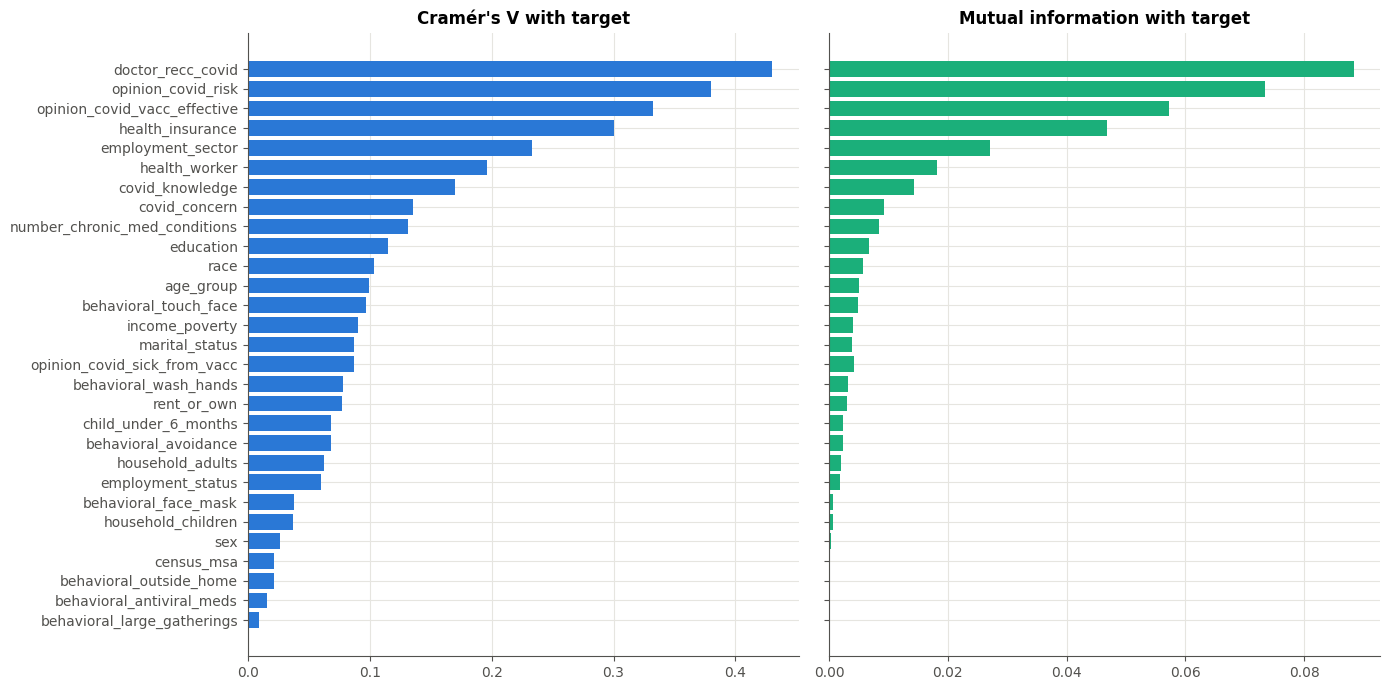

In [5]:
# Two complementary association rankings: Cramér's V (chi-square based) and mutual information
enc = train_raw[FEATURES].astype(str).apply(lambda s: s.astype('category').cat.codes)   # NaN becomes its own level
mi = pd.Series(mutual_info_classif(enc, train_raw[TARGET], discrete_features=True, random_state=RANDOM_STATE),
               index=FEATURES)
rank = pd.DataFrame({'cramers_v': assoc, 'mutual_info': mi}).sort_values('cramers_v')

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
axes[0].barh(rank.index, rank['cramers_v'], color=BLUE); axes[0].set_title("Cramér's V with target")
axes[1].barh(rank.index, rank['mutual_info'], color=AQUA); axes[1].set_title('Mutual information with target')
plt.tight_layout(); savefig('03_association_rank'); plt.show()

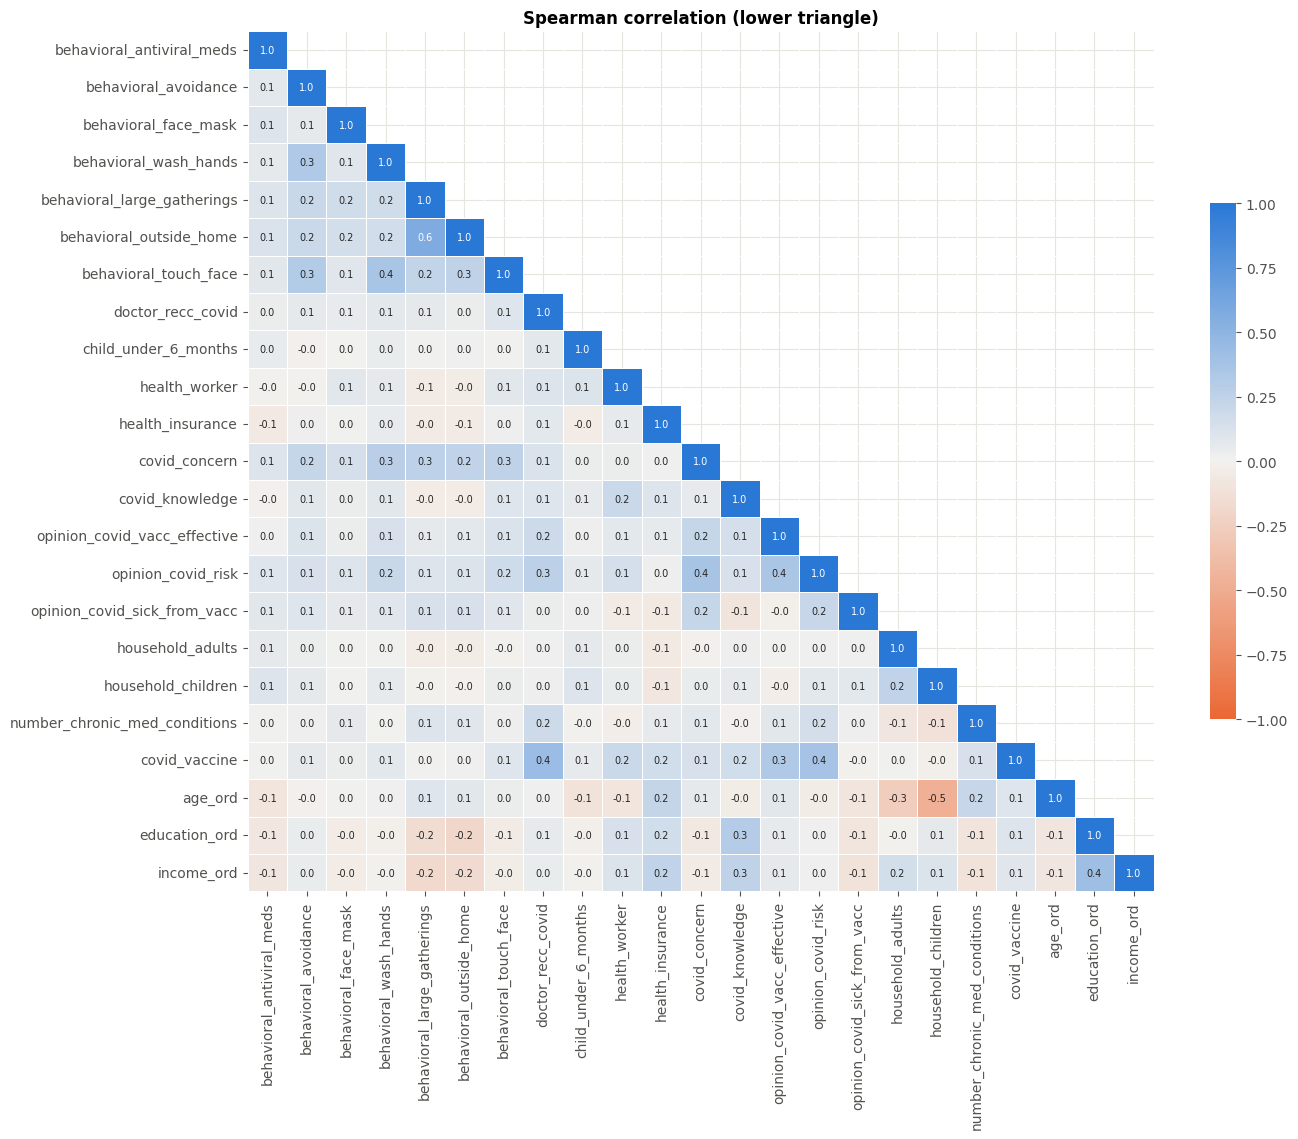

Strongest pairwise correlations:
behavioral_outside_home  behavioral_large_gatherings     0.58
age_ord                  household_children             -0.47
covid_vaccine            doctor_recc_covid               0.43
income_ord               education_ord                   0.42
covid_vaccine            opinion_covid_risk              0.38
opinion_covid_risk       covid_concern                   0.37
behavioral_touch_face    behavioral_wash_hands           0.36
opinion_covid_risk       opinion_covid_vacc_effective    0.35
dtype: float64


In [6]:
# Spearman correlation among ordinal / binary features (and the target) – looks for redundancy
num_view = train_raw[BINARY + ORDINAL_NUM + [TARGET]].copy()
num_view[OPINION[:2]] = num_view[OPINION[:2]].replace(0, np.nan)
num_view['age_ord'] = train_raw['age_group'].map({a: i for i, a in enumerate(AGE_ORDER)})
num_view['education_ord'] = train_raw['education'].map({a: i for i, a in enumerate(EDU_ORDER)})
num_view['income_ord'] = train_raw['income_poverty'].map({a: i for i, a in enumerate(INC_ORDER)})
corr = num_view.corr(method='spearman')

fig, ax = plt.subplots(figsize=(14, 11.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIV_CMAP, center=0, vmin=-1, vmax=1, annot=True, fmt='.1f',
            annot_kws={'size': 7}, linewidths=0.5, linecolor='white', ax=ax, cbar_kws={'shrink': 0.6})
ax.set_title('Spearman correlation (lower triangle)'); plt.tight_layout(); savefig('03_correlation'); plt.show()

pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack().sort_values(key=abs, ascending=False)
print('Strongest pairwise correlations:'); print(pairs.head(8).round(2))

**Strongest predictors of acceptance:** a **doctor's recommendation** (≈70 % vs 22 % acceptance), the person's **opinion of vaccine effectiveness**
and **perceived risk of COVID**, then **health worker**, **health insurance**, COVID concern and age. Socio-demographic variables
(race, sex, marital status, household size, MSA) matter much less. Correlations between features are moderate (|ρ| ≤ ≈0.6, e.g. among the
behavioural questions, and `household_children`–`child_under_6_months`), so multicollinearity is not severe – but L2/elastic-net
regularisation is still sensible for logistic regression.

### 3.8 Interactions

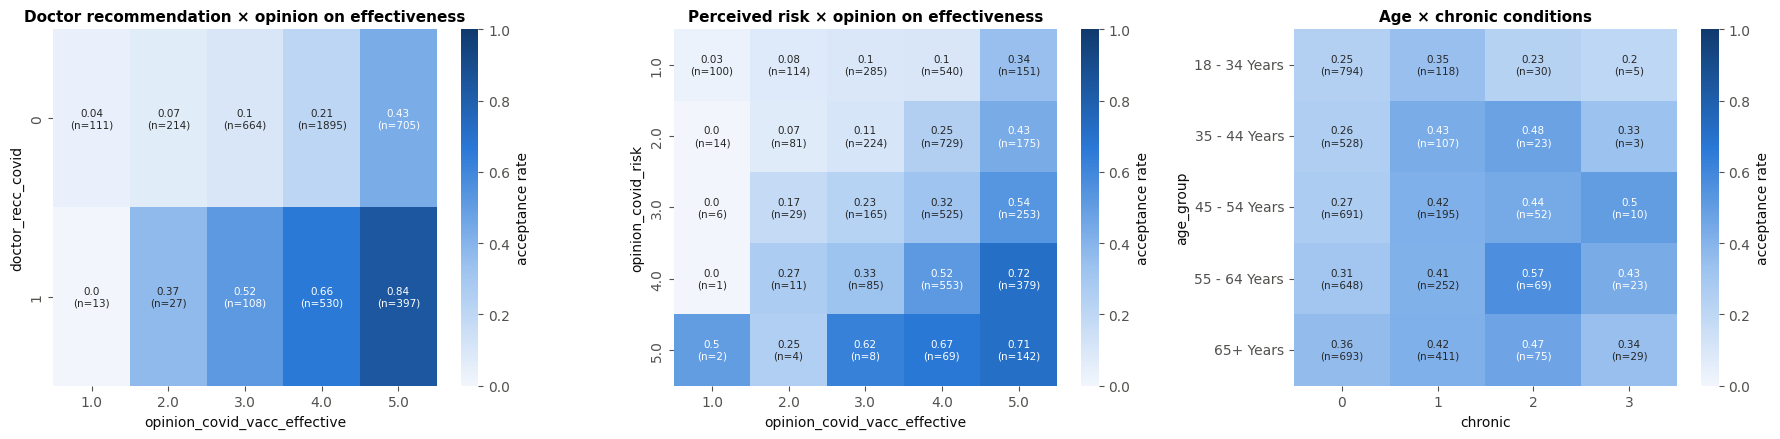

In [7]:
d = train_raw.assign(opinion_covid_vacc_effective=train_raw['opinion_covid_vacc_effective'].replace(0, np.nan),
                     opinion_covid_risk=train_raw['opinion_covid_risk'].replace(0, np.nan),
                     chronic=train_raw['number_chronic_med_conditions'].clip(upper=3))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (r, c, title) in zip(axes, [('doctor_recc_covid', 'opinion_covid_vacc_effective', 'Doctor recommendation × opinion on effectiveness'),
                                    ('opinion_covid_risk', 'opinion_covid_vacc_effective', 'Perceived risk × opinion on effectiveness'),
                                    ('age_group', 'chronic', 'Age × chronic conditions')]):
    pt = d.pivot_table(index=r, columns=c, values=TARGET, aggfunc='mean')
    n = d.pivot_table(index=r, columns=c, values=TARGET, aggfunc='size')
    if r == 'age_group':
        pt, n = pt.reindex(AGE_ORDER), n.reindex(AGE_ORDER)
    annot = pt.round(2).astype(str) + '\n(n=' + n.fillna(0).astype(int).astype(str) + ')'
    sns.heatmap(pt, annot=annot, fmt='', cmap=SEQ_CMAP, vmin=0, vmax=1, ax=ax, annot_kws={'size': 7.5},
                cbar_kws={'label': 'acceptance rate'})
    ax.set_title(title, fontsize=11)
plt.tight_layout(); savefig('03_interactions'); plt.show()

* Doctor recommendation and belief in effectiveness **reinforce each other**: from ≈3 % (doctor did not recommend, "not at all effective")
  to ≈87 % (recommended, "very effective"). Interactions like this favour tree-based models, but the effects are mostly monotone and
  additive on the log-odds scale, so logistic regression should also be competitive.
* Age and chronic conditions raise acceptance *and* hospitalisation risk – the people the model finds most likely to accept are often the
  ones where vaccination saves the most money.

### 3.9 Cost-driver view: where is the money?

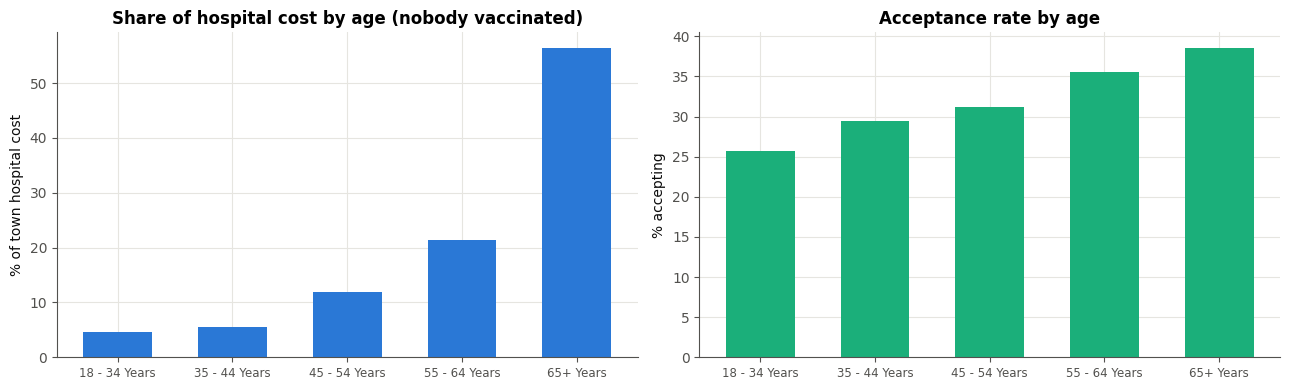

,people,accept_rate,mean_risk,hosp_cost_if_nobody_vacc,share_of_hosp_cost
age_group,,,,,
18 - 34 Years,947,0.258,0.019,735654.448,0.047
35 - 44 Years,661,0.295,0.032,872196.958,0.055
45 - 54 Years,948,0.312,0.049,1885498.185,0.119
55 - 64 Years,992,0.356,0.083,3381346.362,0.214
65+ Years,1208,0.386,0.180,8911557.993,0.565


In [8]:
tr_view = train_raw.assign(p_hosp=MAIN.p_unvacc(train_raw))
g = tr_view.groupby('age_group').agg(people=(TARGET, 'size'), accept_rate=(TARGET, 'mean'), mean_risk=('p_hosp', 'mean'),
                                     hosp_cost_if_nobody_vacc=('p_hosp', lambda p: HOSP_COST * p.sum())).reindex(AGE_ORDER)
g['share_of_hosp_cost'] = g['hosp_cost_if_nobody_vacc'] / g['hosp_cost_if_nobody_vacc'].sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(g.index, g['share_of_hosp_cost'] * 100, color=BLUE, width=0.6)
axes[0].set_ylabel('% of town hospital cost'); axes[0].set_title('Share of hospital cost by age (nobody vaccinated)')
axes[1].bar(g.index, g['accept_rate'] * 100, color=AQUA, width=0.6)
axes[1].set_ylabel('% accepting'); axes[1].set_title('Acceptance rate by age')
for ax in axes:
    ax.tick_params(axis='x', labelsize=8.5)
plt.tight_layout(); savefig('03_cost_drivers'); plt.show()
g.round(3)

The 65+ group (≈25 % of residents) generates ≈60 % of the potential hospital bill. Getting the *elderly* decisions right matters far more than
getting the *young* ones right – exactly what the personal threshold encodes.

### 3.10 EDA → pre-processing decisions

| Finding | Decision |
|---|---|
| `respondent_id` is random | drop |
| 0 in opinion scales = disguised missing | recode to NaN |
| `employment_sector` missing for non-employed | new category `not_employed` |
| Missingness is informative (lower acceptance) | test "Missing" category + missing-indicator flags + count of missing answers |
| Ordered categories (age, education, income) | test ordinal encoding vs one-hot |
| Rare `employment_sector` levels | group levels with < 30 people (`min_frequency`) |
| Long tail of chronic conditions | top-code at 3 (binning) |
| Many related behaviour / opinion questions | engineered `behaviour_score` (sum) and `vacc_attitude` (effective + risk − worried) |
| Imbalance 33/67 | no resampling – keep probabilities calibrated; handle via cost-based thresholds |
| No train/test shift | standard stratified CV is a good proxy for the test set |

**Next:** notebook 04 implements and compares these pre-processing decisions.